# AeroGuard: Modeling, Benchmarking, Explainability & Uncertainty Quantification

**Author:** Senior Machine Learning Engineer / Applied ML Research Team  
**Dataset:** NASA C-MAPSS FD001 Turbofan Degradation Simulation  
**Objective:** End-to-end model benchmarking, engine-level GroupKFold CV, official test evaluation, TreeSHAP attribution, and Split Conformal Prediction intervals.

---

## 1. Experimental Methodology & Leakage Prevention

### 1.1 Strict Group Separation by Engine
In time series degradation modeling, splitting observations randomly causes severe temporal leakage between adjacent cycles ($t$ and $t+1$) of the same engine.
We enforce strict **GroupKFold** ($K=5$) over `engine_id`:
$$\mathcal{E}_{\text{val}}^{(k)} \cap \mathcal{E}_{\text{train}}^{(k)} = \emptyset$$

### 1.2 Causal Temporal Features
All rolling windows ($\mu_{t,w}, \sigma_{t,w}$) and differences ($\Delta_w x_t$) are strictly backward-looking ($[t-w+1, t]$) and partitioned by `engine_id`.

### 1.3 Target Capping Formulation
To reflect the physical plateau of early-life operation:
$$RUL_{\text{capped}}(i, t) = \min(T_i - t, RUL_{\text{cap}})$$


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project modules are resolvable
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root))

from src.data.loader import load_fd001_raw
from src.features.engineer import prepare_feature_matrix
from src.models.train import build_pipeline, evaluate_on_test_fleet, run_engine_group_cv
from src.evaluation.metrics import compute_regression_metrics
from src.explainability.shap_explainer import AeroGuardExplainer
from src.models.uncertainty import SplitConformalPredictor

train_df, test_df, rul_series = load_fd001_raw(project_root / 'data' / 'raw')
print(f'Train Fleet: {len(train_df)} snapshots across {train_df["engine_id"].nunique()} engines')
print(f'Test Fleet:  {len(test_df)} snapshots across {test_df["engine_id"].nunique()} engines')


D:\projects\AeroGuard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train Fleet: 20631 snapshots across 100 engines
Test Fleet:  13096 snapshots across 100 engines


## 2. Experimental Benchmark Results

We load the pre-computed cross-validation and official test fleet metrics generated by our benchmark suite.


In [2]:
exp_log_path = project_root / 'results' / 'metrics' / 'experiment_log.csv'
df_exp = pd.read_csv(exp_log_path)
df_exp


,Experiment_ID,Model,Features,Target_Cap,CV_MAE,CV_RMSE,CV_R2,Test_MAE,Test_RMSE,Test_R2,Test_NASA_Score
0,EXP-01,MEDIAN,raw,125,35.75,44.70,-0.151,39.08,49.82,-0.437,166570.5
1,EXP-02,LINEAR,raw,125,17.75,21.66,0.729,17.61,21.91,0.722,1318.9
2,EXP-03,LINEAR,temporal,125,15.75,19.30,0.785,15.34,19.35,0.783,713.1
3,EXP-04,RIDGE,temporal,125,15.75,19.30,0.785,15.35,19.37,0.783,713.7
4,EXP-05,RF,temporal,125,13.32,18.55,0.802,14.12,19.44,0.781,1155.1
5,EXP-06,XGB,temporal,125,12.78,17.61,0.821,13.28,17.86,0.815,678.7


### 2.1 Benchmark Comparison Visualization
Comparing official test set Root Mean Squared Error (RMSE) and NASA Asymmetric Prognostics Score across models.


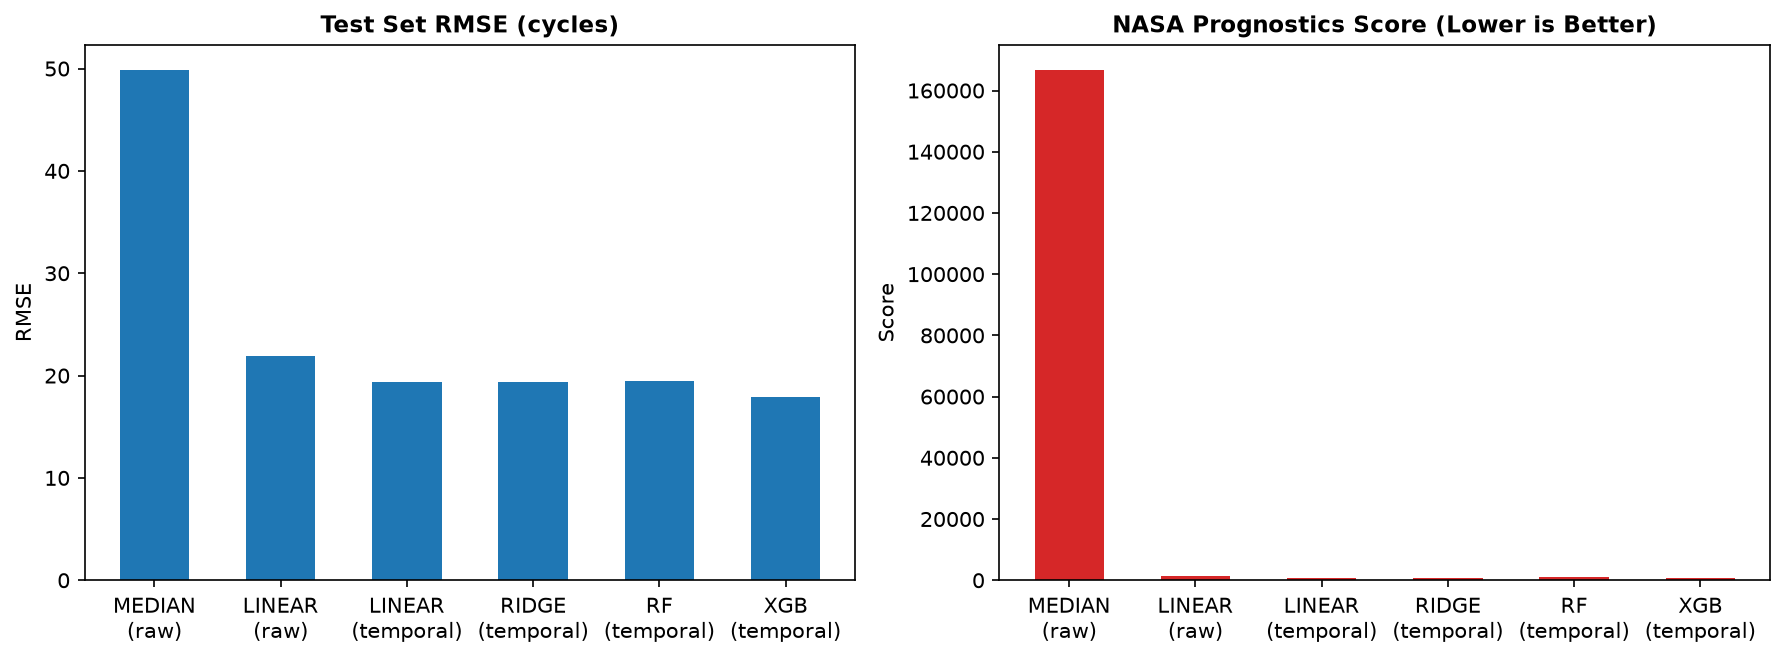

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)
labels = [f"{r['Model']}\n({r['Features']})" for _, r in df_exp.iterrows()]

ax1.bar(labels, df_exp["Test_RMSE"], color="#1f77b4", width=0.55)
ax1.set_title("Test Set RMSE (cycles)", fontsize=11, fontweight="bold")
ax1.set_ylabel("RMSE", fontsize=10)

ax2.bar(labels, df_exp["Test_NASA_Score"], color="#d62728", width=0.55)
ax2.set_title("NASA Prognostics Score (Lower is Better)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Score", fontsize=10)

plt.tight_layout()
plt.show()


## 3. Target Capping Sensitivity Analysis

We examine how the piecewise linear ceiling threshold affects prediction error and asymmetric penalty.


In [4]:
cap_path = project_root / 'results' / 'metrics' / 'target_cap_sensitivity.csv'
df_cap = pd.read_csv(cap_path)
df_cap


,RUL_Cap,Cap_Label,Test_MAE,Test_RMSE,Test_R2,Test_NASA_Score
0,200,Uncapped,23.201643,31.645944,0.420069,20128.302398
1,100,100,14.467071,19.680703,0.775704,563.061902
2,115,115,12.628008,17.416165,0.824351,521.747609
3,125,125,13.282149,17.861301,0.815258,678.711034
4,130,130,13.711256,18.365866,0.804673,795.209815
5,140,140,14.873802,19.816334,0.772602,1130.712533
6,150,150,16.273597,21.533807,0.731477,1704.548313


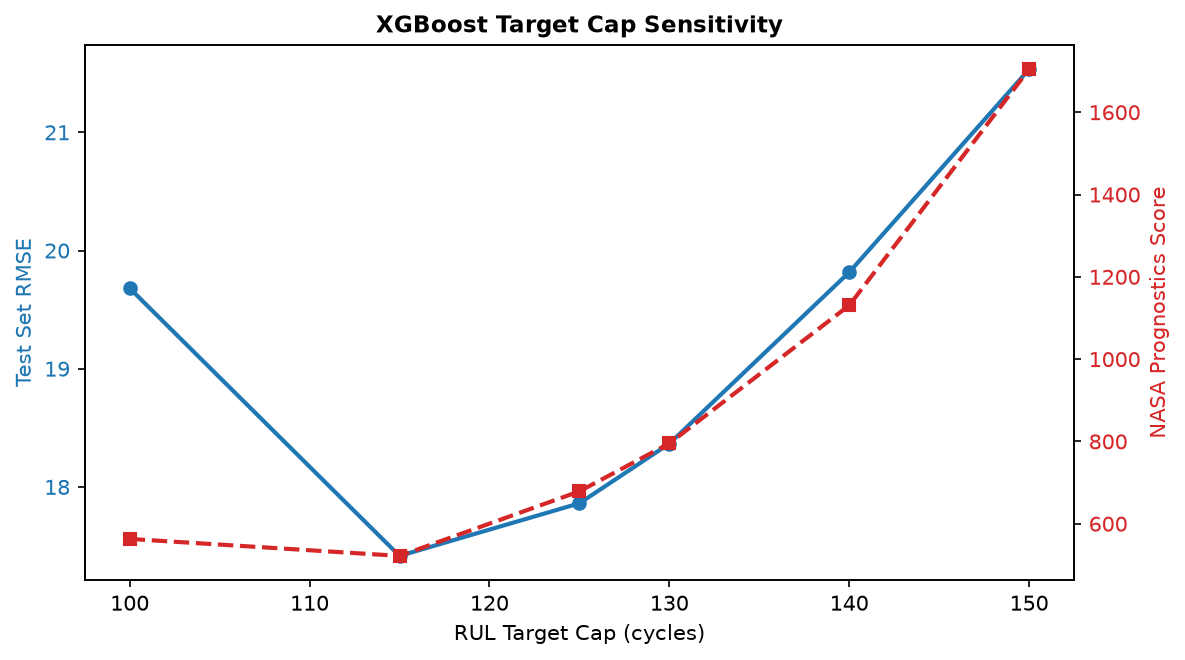

In [5]:
fig, ax1 = plt.subplots(figsize=(8, 4.5), dpi=150)
df_cap_sub = df_cap[df_cap["RUL_Cap"] <= 150]

color = "#1f77b4"
ax1.set_xlabel("RUL Target Cap (cycles)", fontsize=10)
ax1.set_ylabel("Test Set RMSE", color=color, fontsize=10)
ax1.plot(df_cap_sub["RUL_Cap"], df_cap_sub["Test_RMSE"], marker="o", color=color, linewidth=2, label="Test RMSE")
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "#d62728"
ax2.set_ylabel("NASA Prognostics Score", color=color, fontsize=10)
ax2.plot(df_cap_sub["RUL_Cap"], df_cap_sub["Test_NASA_Score"], marker="s", color=color, linewidth=2, linestyle="--", label="NASA Score")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("XGBoost Target Cap Sensitivity", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. SHAP Feature Attribution & Model Explainability

We compute TreeSHAP values for our champion XGBoost model on the test fleet endpoints.


In [6]:
import joblib
import shap

models_dir = project_root / 'models'
xgb_artifact = joblib.load(models_dir / 'xgboost_best.joblib')
pipeline = xgb_artifact['pipeline']
feature_names = xgb_artifact['feature_names']

# Compute test endpoint predictions
from src.features.engineer import INFORMATIVE_SENSORS, compute_temporal_features
test_proc = compute_temporal_features(test_df, sensors=INFORMATIVE_SENSORS, windows=(5, 15))
final_cycle_indices = test_proc.groupby("engine_id")["cycle"].idxmax()
test_endpoints = test_proc.loc[final_cycle_indices].sort_values("engine_id").reset_index(drop=True)
X_test = test_endpoints[feature_names]

explainer = AeroGuardExplainer(pipeline, feature_names)
explanation = explainer.explain(X_test)

# Display Top 10 Features by Mean Absolute SHAP
imp_df = explainer.get_global_importance(X_test)
imp_df.head(10)


,Feature,Mean_Abs_SHAP
0,s_4_roll_mean_5,8.338076
1,s_11_roll_mean_5,5.735796
2,s_9_roll_mean_5,3.763898
3,s_3_roll_mean_15,3.615663
4,s_15_roll_mean_5,3.536821
5,s_9_roll_mean_15,2.770112
6,s_2_roll_mean_5,2.581006
7,s_14_roll_mean_15,1.638208
8,s_3_roll_mean_5,1.229454
9,s_21_roll_mean_5,1.150791


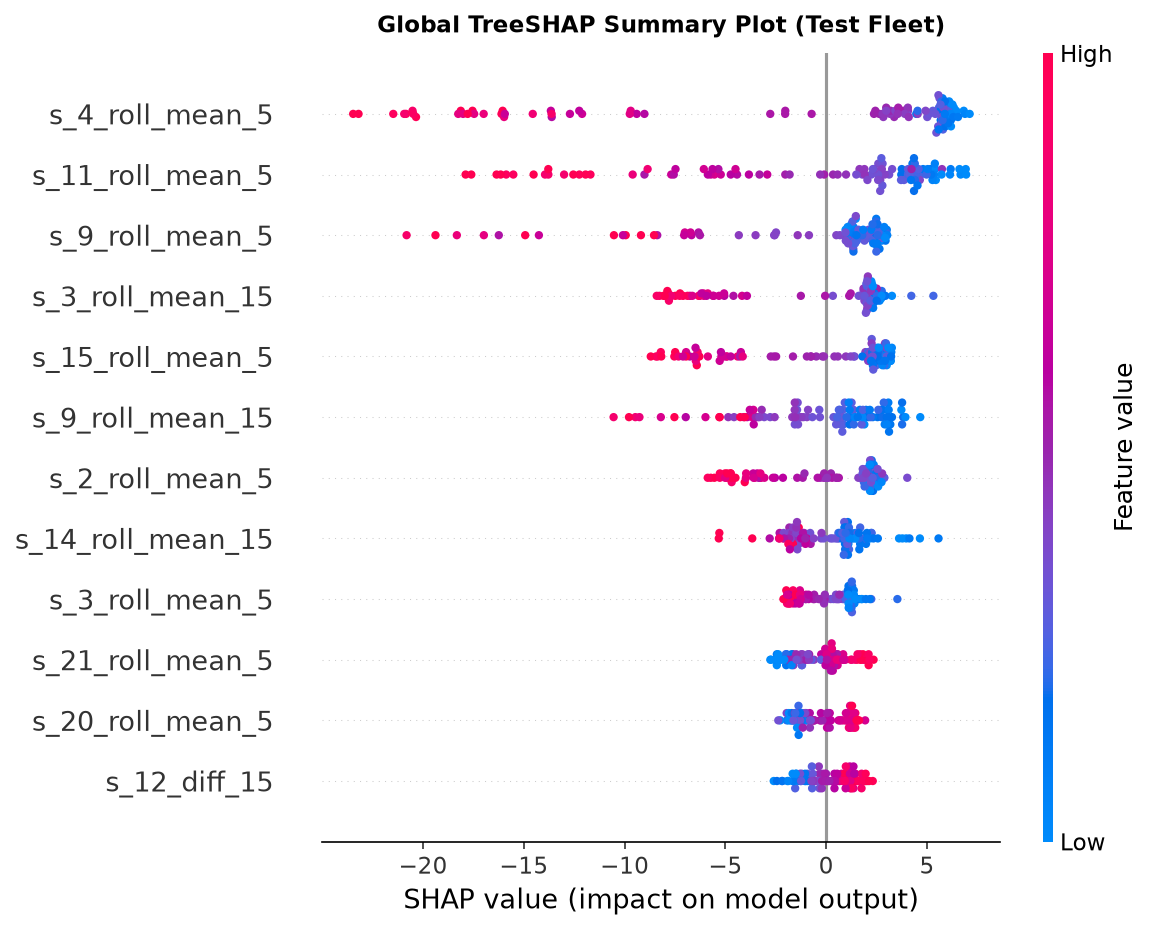

In [7]:
plt.figure(figsize=(10, 6), dpi=150)
shap.summary_plot(explanation, X_test, show=False, max_display=12)
plt.title("Global TreeSHAP Summary Plot (Test Fleet)", fontsize=11, fontweight="bold", pad=10)
plt.tight_layout()
plt.show()


## 5. Split Conformal Uncertainty Estimation

We load the calibrated Split Conformal Predictor to construct distribution-free 90% confidence intervals.


In [8]:
conformal = joblib.load(models_dir / 'conformal_calibrator.joblib')
y_true = rul_series.sort_index().to_numpy()
y_pred = np.maximum(0.0, pipeline.predict(X_test))

cov_stats = conformal.evaluate_coverage(y_true, y_pred)
print(f"Conformal Calibration Margin: ±{conformal.quantile_:.2f} cycles")
print(f"Nominal Confidence Level:    {cov_stats['nominal_coverage']*100:.0f}%")
print(f"Empirical Test Coverage:     {cov_stats['empirical_coverage']*100:.1f}%")
print(f"Mean Interval Width:         {cov_stats['mean_interval_width']:.1f} cycles")


Conformal Calibration Margin: ±26.21 cycles
Nominal Confidence Level:    90%
Empirical Test Coverage:     85.0%
Mean Interval Width:         50.5 cycles


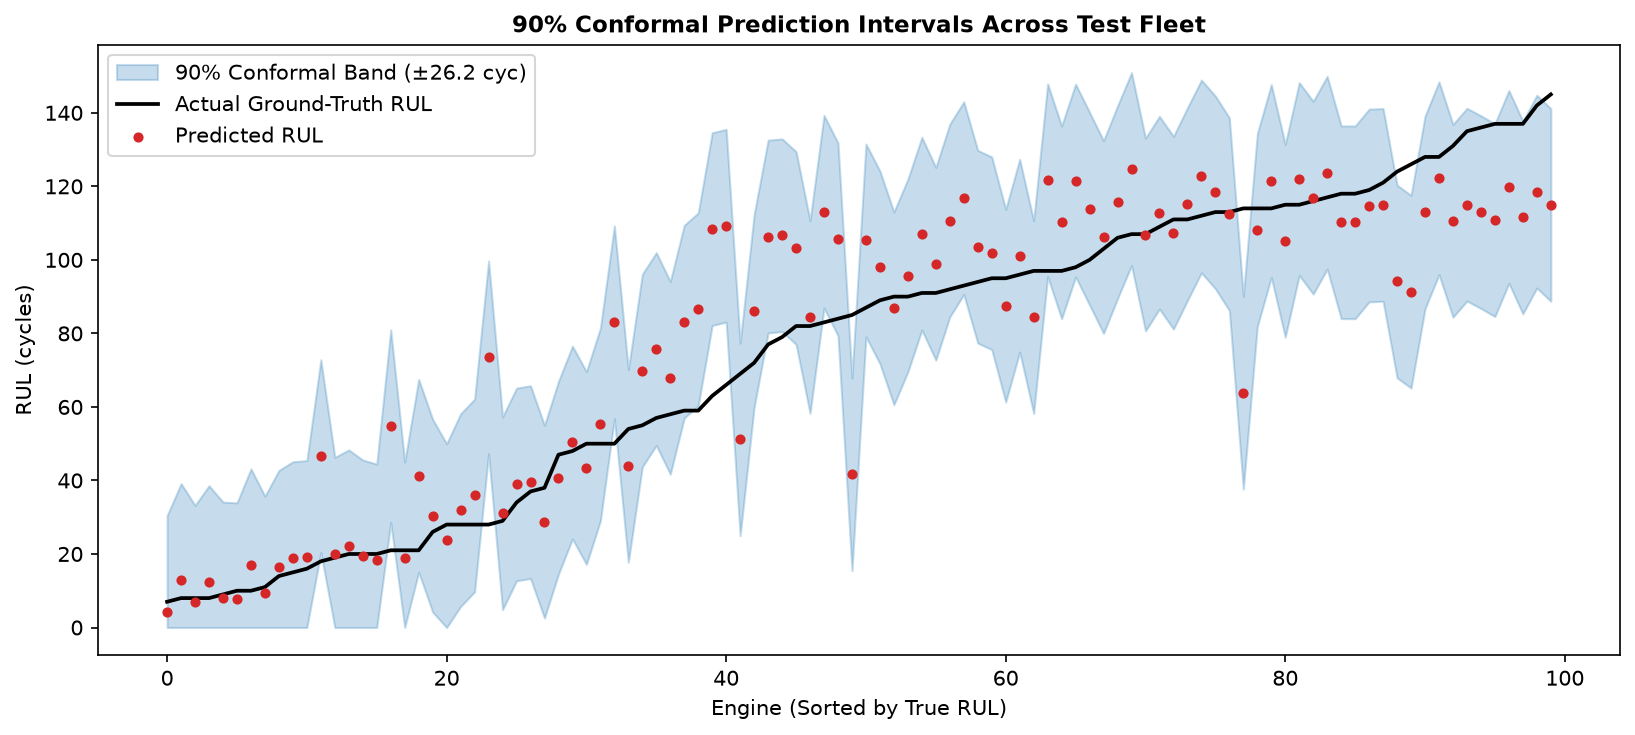

In [9]:
lower_bounds, upper_bounds = conformal.predict_interval(y_pred)
sort_idx = np.argsort(y_true)

fig, ax = plt.subplots(figsize=(11, 5), dpi=150)
x_axis = np.arange(len(y_true))
ax.fill_between(x_axis, lower_bounds[sort_idx], upper_bounds[sort_idx], color="#1f77b4", alpha=0.25, label=f"90% Conformal Band (±{conformal.quantile_:.1f} cyc)")
ax.plot(x_axis, y_true[sort_idx], "k-", linewidth=1.8, label="Actual Ground-Truth RUL")
ax.scatter(x_axis, y_pred[sort_idx], color="#d62728", s=15, label="Predicted RUL", zorder=3)
ax.set_title("90% Conformal Prediction Intervals Across Test Fleet", fontsize=11, fontweight="bold")
ax.set_xlabel("Engine (Sorted by True RUL)", fontsize=10)
ax.set_ylabel("RUL (cycles)", fontsize=10)
ax.legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.show()
